# Future field with a spatial receptive field and convergent remapping

Does figure 4's future-field model still produce the relational spectrum of the example neurons when
the receptive field depends on **distance** (a 2-D Gaussian in space, not a von Mises in direction)
and remapping is **convergent** (Zirnsak et al., 2014: remapped fields are pulled toward the saccade
target)? The model is `ff_distance_lib.DistanceFutureFieldModel`; its docstring has the equations,
and the second figure below draws it.

**Figure 1** (6 rows × 5 neurons). Columns: `figure_4/figure_example_neurons.ipynb`'s `UNITS`, read
from that notebook. Each ring shows the stimuli that drive the neuron most at each inter-object
angle in `SEPARATIONS`, in `figure_example_neurons`' style.

1. **Data**: the neuron's measured maximum chords (`figure_example_neurons`' procedure).
2. **Future field (figure 4)**: figure 4's cached all-trial fit of its future-field model
   (direction-only von Mises receptive field, perfect remapping).
3. – 6. **Distance future field** at each convergence κ in `CONVERGENCES` (0 = perfect remapping,
   1 = every future field on the saccade target), with the receptive-field centre fixed at
   `RF_ECC` ring radii. Each is fit to the neuron's 2-object trials by figure 4's optimiser, with
   κ and `RF_ECC` held fixed and the other five parameters free.

Model rows draw every local maximum of the noise-free predicted rate, up to `SEPARATIONS[sep]` per
separation (as `figure_example_model_neurons.ipynb`). Under each model ring, ΔLL is the all-trial
log-likelihood per trial above a constant-rate model (nats/trial), so rows can be compared for fit.

Figure 1 is saved to `OUTPUT`; figure 2 is not saved. Figure sizes are CONFIG parameters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

import common
common.set_style()
import ff_distance_lib as fdl          # puts figure_4/ on sys.path
import data_lib
import example_neurons_lib as enl
import models_lib as ml
import tuning_lib

# ══ The model ═════════════════════════════════════════════════════════════════
RF_ECC = 1.5                     # receptive-field centre, in ring radii (held fixed in every fit)
CONVERGENCES = (0.0, 1 / 4, 1 / 2)   # κ for rows 3-6: 0 = perfect remapping, 1 = on target
INCLUDE_TARGET = False           # True: the saccade target also drives its own future field
                                 #   (a per-trial constant; see ff_distance_lib)

# ══ Figure 1: example neurons × models ════════════════════════════════════════
OUTPUT = 'distance_future_field_examples.pdf'
UNITS = fdl.example_units()      # (subject, session, unit, rotation_deg), from figure_example_neurons
SEPARATIONS = {180: 1, 130: 2, 80: 2}           # inter-object angle -> how many chords
N_DENSE = 180                                   # data row: chord midpoints sampled (2 deg)
MIN_PROMINENCE_FRAC = 0.1                       # data row: peak prominence (fraction of range)
WINDOW_DEG = data_lib.notebook_literal(str(fdl.FIGURE_4 / 'tuning_plots.ipynb'),
                                       'SIMILARITY_WINDOW_DEG')
SMOOTH_DEG = data_lib.notebook_literal(str(fdl.FIGURE_4 / 'tuning_plots.ipynb'),
                                       'LINE_SMOOTH_DEG_2OBJ')
ROTATE = True                    # turn each ring by its unit's rotation_deg (RF up)
SHOW_DLL = False                 # ΔLL (nats/trial) under each model ring
FIGSIZE_EXAMPLES = (8.2, 10.6)   # (width, height), inches
ROW_LABEL_X = -0.12              # row labels' x, in the first column's axes fraction

# ══ Figure 2: schematic of the remapping ══════════════════════════════════════
SCHEMATIC_THETA_DEG = 90.0       # receptive field direction (up)
SCHEMATIC_SIGMA = 0.4            # receptive-field s.d., ring radii
SCHEMATIC_PHI_A_DEG = 146.0      # object A
SCHEMATIC_PHI_B_DEG = 230.0      # object B = the saccade target
SCHEMATIC_KAPPAS = (0.0, 0.5, 1.0)
FIGSIZE_SCHEMATIC = (14.0, 4.4)

# ══ Drawing ═══════════════════════════════════════════════════════════════════
RING_RADIUS = 0.43               # in axes fractions, as figure 2/4's rings
CHORD_LW = 2.0
DOT_SIZE = 14
SHOW_FIXATION_CROSS = False
TITLE_PAD = -2.0
MAX_COLOR = tuning_lib.FIRING_RATE_CMAP(1.0)
RF_COLOR = 'tab:blue'            # schematic: the receptive field
FF_COLOR = 'tab:orange'          # schematic: the future field

## Fits and maximum chords

In [2]:
def model_label(kappa):
    return f'Convergence = {kappa:.2f}'


rows = ['Data', 'Future field\n(figure 4)'] + [model_label(k) for k in CONVERGENCES]
grid = [[None] * len(UNITS) for _ in rows]      # (chords, ΔLL or None)
table = []
for col, (s, ses, u, _) in enumerate(UNITS):
    ch, _ = enl.empirical_chords(s, ses, u, SEPARATIONS, N_DENSE, WINDOW_DEG, SMOOTH_DEG,
                                 MIN_PROMINENCE_FRAC)
    grid[0][col] = (ch, None)

    m4, p4, dll4 = fdl.figure4_fit(s, ses, u)
    grid[1][col] = (enl.drawn_model_chords(m4, p4, SEPARATIONS, tie_tol=None)[0], dll4)
    table.append(dict(unit=u, model='figure 4 FF', dll=dll4, theta_deg=np.degrees(p4['theta']),
                      width=p4['width'], a_ret=p4['amplitude_retinotopic'],
                      a_ff=p4['amplitude_remapped'], baseline=p4['baseline']))

    for r, kappa in enumerate(CONVERGENCES, start=2):
        model = fdl.DistanceFutureFieldModel(RF_ECC, kappa, INCLUDE_TARGET)
        p, dll = fdl.cached_fit(s, ses, u, model)
        grid[r][col] = (enl.drawn_model_chords(model, p, SEPARATIONS, tie_tol=None)[0], dll)
        table.append(dict(unit=u, model=f'distance κ={kappa:.2f}', dll=dll,
                          theta_deg=np.degrees(p['theta']) % 360, width=p['width'],
                          a_ret=p['amplitude_retinotopic'], a_ff=p['amplitude_remapped'],
                          baseline=p['baseline']))

table = pd.DataFrame(table)
# width: figure 4's von Mises width parameter; the distance model's σ in ring radii.
print(table.round(3).to_string(index=False))

 unit           model   dll  theta_deg  width  a_ret   a_ff  baseline
   89     figure 4 FF 2.875     51.698  0.397 19.948  0.441     9.506
   89 distance κ=0.00 2.877     51.719  0.485 33.938  0.821     9.513
   89 distance κ=0.25 2.876     51.668  0.486 34.014  0.951     9.502
   89 distance κ=0.50 2.876     51.637  0.487 33.987  1.932     9.482
   78     figure 4 FF 4.675    320.726  0.475 28.742  9.617    14.538
   78 distance κ=0.00 4.603    321.097  0.580 44.207  8.606    15.444
   78 distance κ=0.25 4.599    321.254  0.576 45.793 10.192    15.326
   78 distance κ=0.50 4.557    321.630  0.570 47.824 14.629    15.368
  129     figure 4 FF 0.445     81.210  0.490  2.261  2.321     2.513
  129 distance κ=0.00 0.460     81.698  0.631  3.178  2.668     2.612
  129 distance κ=0.25 0.481     81.445  0.588  3.660  3.740     2.601
  129 distance κ=0.50 0.477     81.347  0.594  4.027  6.182     2.483
  158     figure 4 FF 3.152    280.694  0.512  9.133 19.674    13.222
  158 distance κ=0.0

saved distance_future_field_examples.pdf


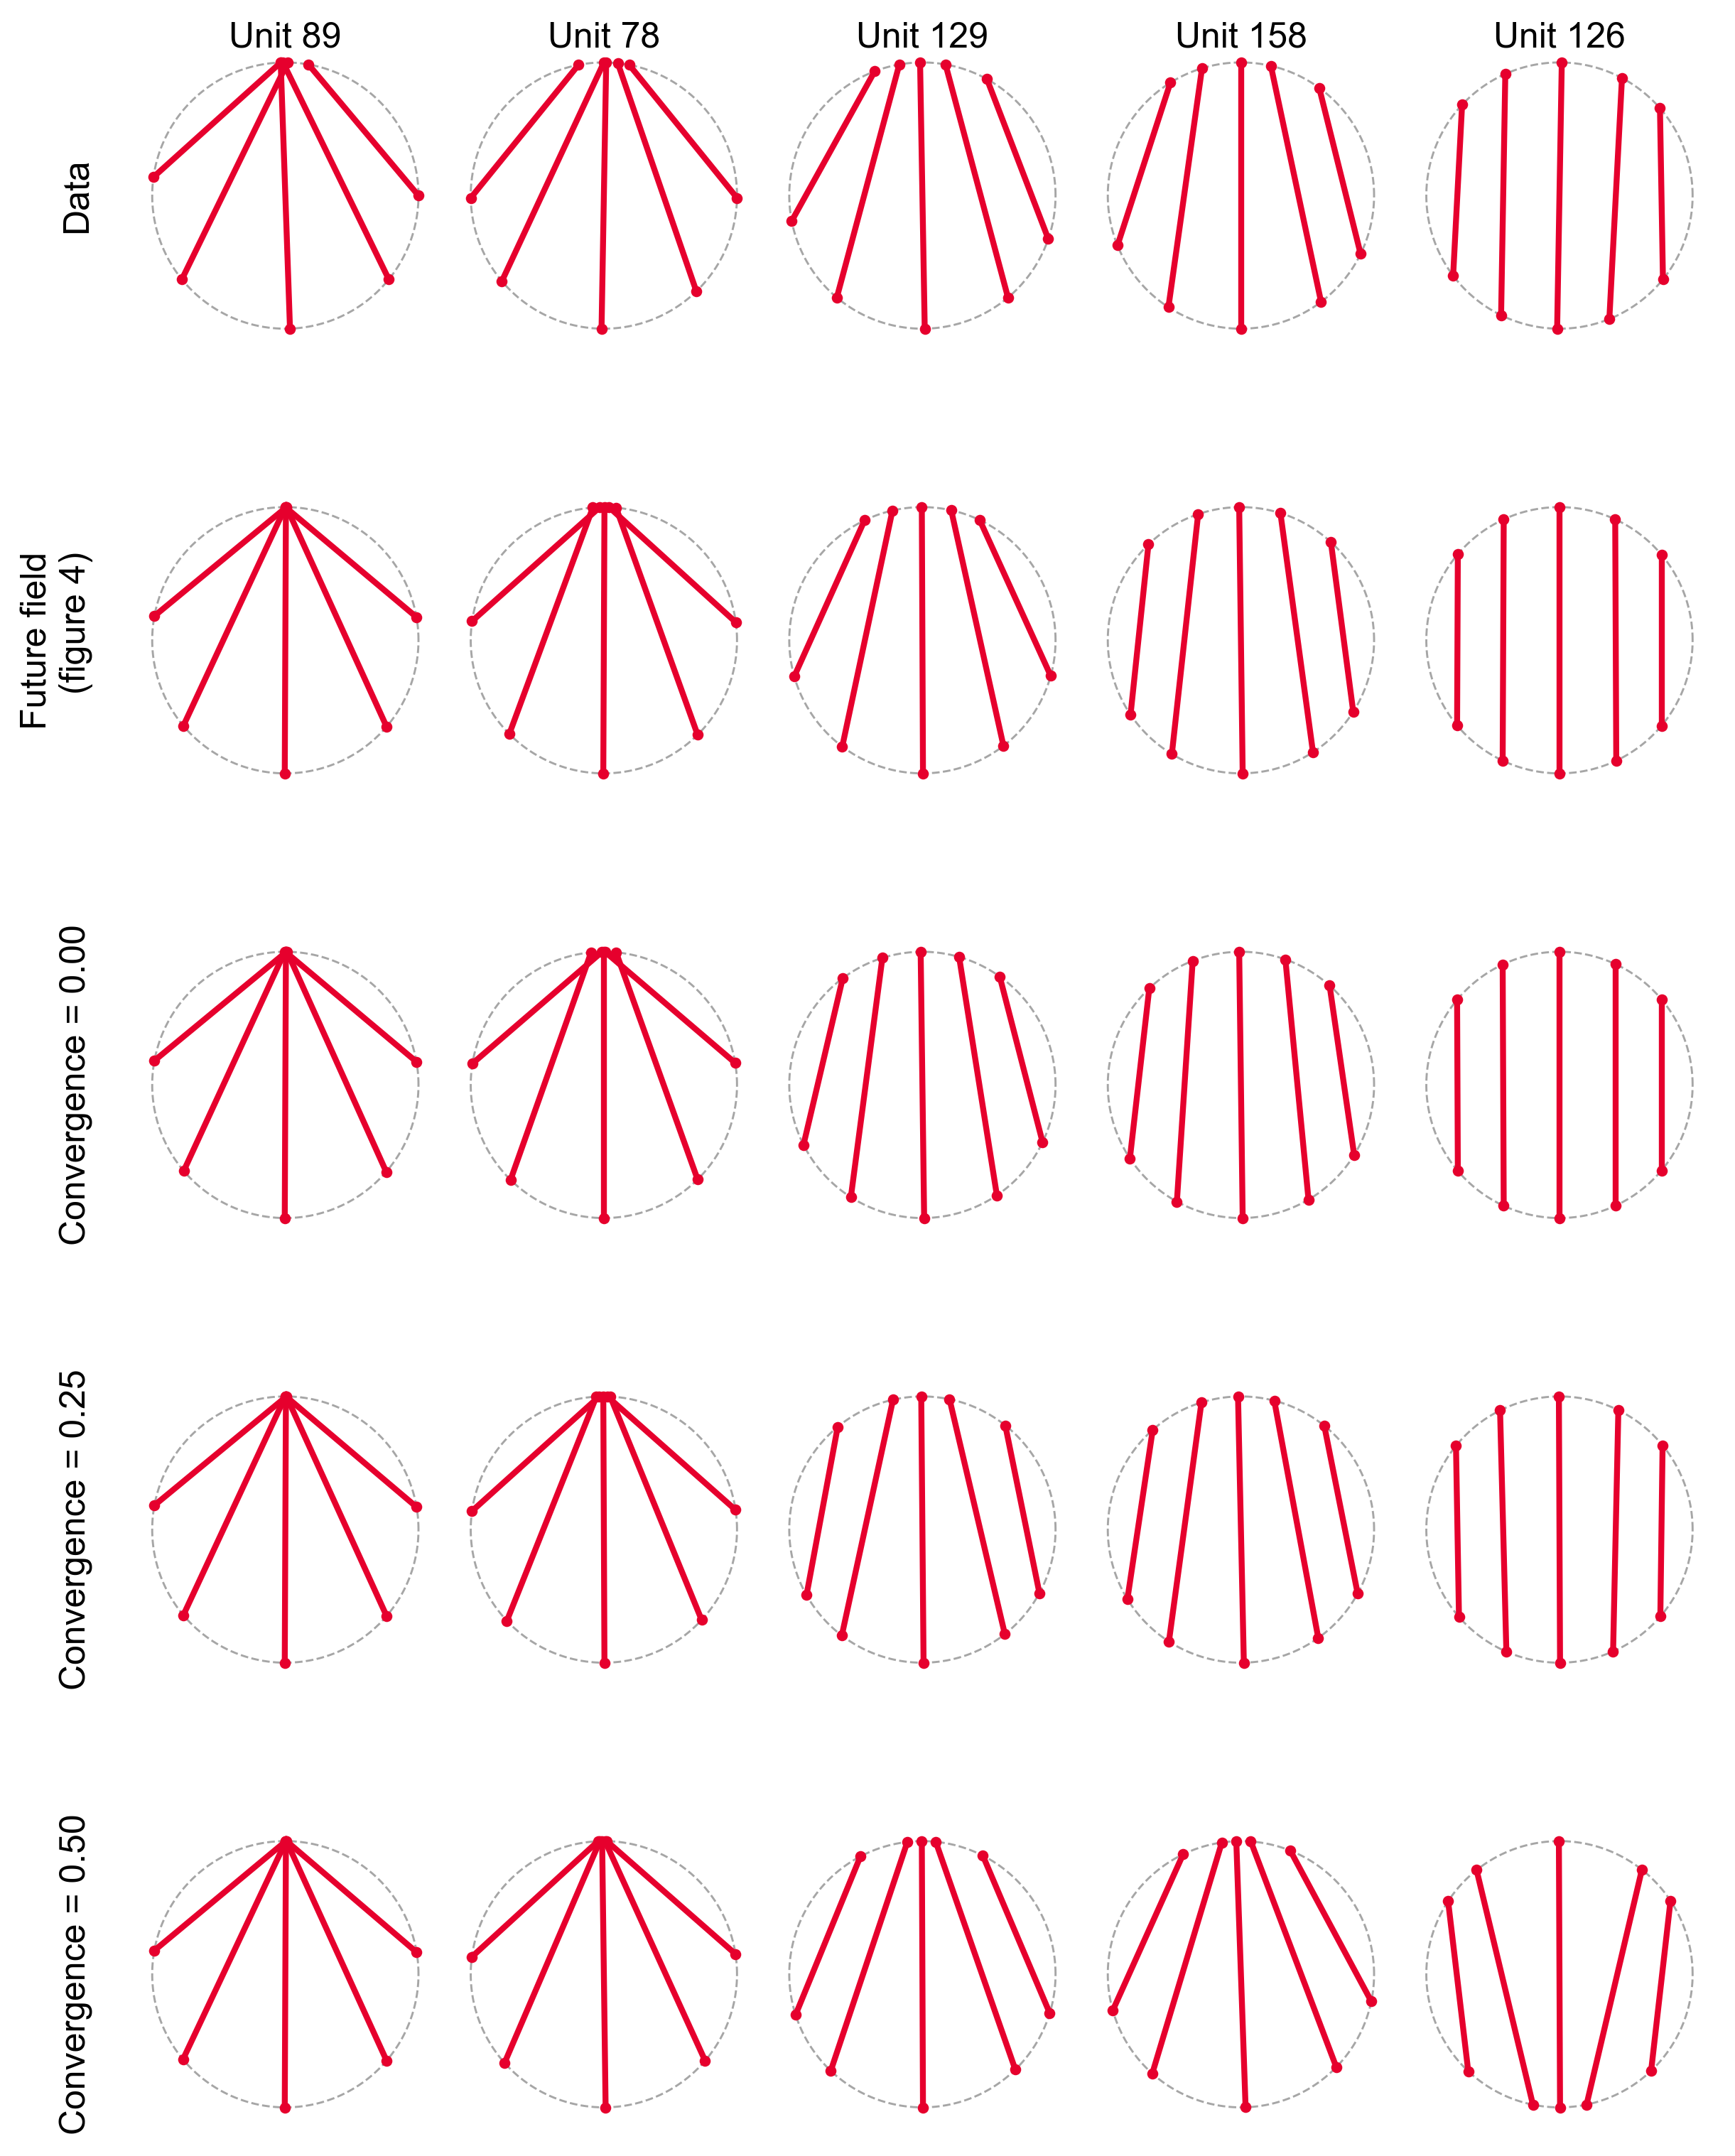

In [3]:
def draw_ring(ax, chords, rot_rad=0.0):
    tuning_lib.pl._prep_stim_ax(ax, RING_RADIUS)
    if not SHOW_FIXATION_CROSS:
        ax.lines[-1].remove()                              # the cross is _prep_stim_ax's last line
    for a, c, *_ in chords:
        x = 0.5 + RING_RADIUS * np.cos(np.array([a, c]) + rot_rad)
        y = 0.5 + RING_RADIUS * np.sin(np.array([a, c]) + rot_rad)
        ax.plot(x, y, color=MAX_COLOR, lw=CHORD_LW, solid_capstyle='round', zorder=3)
        if DOT_SIZE:
            ax.scatter(x, y, s=DOT_SIZE, color=MAX_COLOR, zorder=4, linewidths=0)


fig, axes = plt.subplots(len(rows), len(UNITS), figsize=FIGSIZE_EXAMPLES, squeeze=False)
for r, label in enumerate(rows):
    for col, (s, ses, u, deg) in enumerate(UNITS):
        ax = axes[r, col]
        ch, dll = grid[r][col]
        draw_ring(ax, ch, np.radians(deg) if ROTATE else 0.0)
        if r == 0:
            ax.set_title(f'Unit {u}', fontsize=12, pad=TITLE_PAD, y=1.0)
        if SHOW_DLL and dll is not None:
            ax.text(0.5, -0.04, f'ΔLL {dll:.2f}', transform=ax.transAxes, ha='center',
                    va='top', fontsize=12)
    axes[r, 0].text(ROW_LABEL_X, 0.5, label, transform=axes[r, 0].transAxes, rotation=90,
                    ha='right', va='center', fontsize=12)
fig.tight_layout(h_pad=0.6, w_pad=0.3)
common.save(fig, OUTPUT)
plt.show()

## The model, drawn

**Figure 2.** One trial, with object B as the planned saccade target. Positions are in ring radii,
fixation at the origin, the dashed circle is the stimulus ring.

* **a, Receptive field** (blue): a circular Gaussian centred at `c`, `RF_ECC` ring radii from
  fixation in direction θ. Each object drives it by the bump's height at its position (`g(p_A)`,
  `g(p_B)`); this is the retinotopic term.
* **b – d, Future field for a saccade to B** (orange). The receptive field is first carried with
  the planned eye movement — translated by the saccade vector, so it sits at `p_B + c` (grey arrow)
  — then pulled toward the target by the fraction κ (red arrow), to `p_B + (1 − κ)·c`. Its size
  does not change. A's drive on it is printed. **b**, κ = 0: perfect remapping, figure 4's
  geometry but with distance mattering. **d**, κ = 1: the future field sits on B, so A's drive
  depends only on how far A is from B.

The full rate adds the mirror-image term (saccade to A, B's drive on that future field):

`rate = b + a_ret·[g(p_A) + g(p_B)] + a_ff·[h_B(p_A) + h_A(p_B)]`

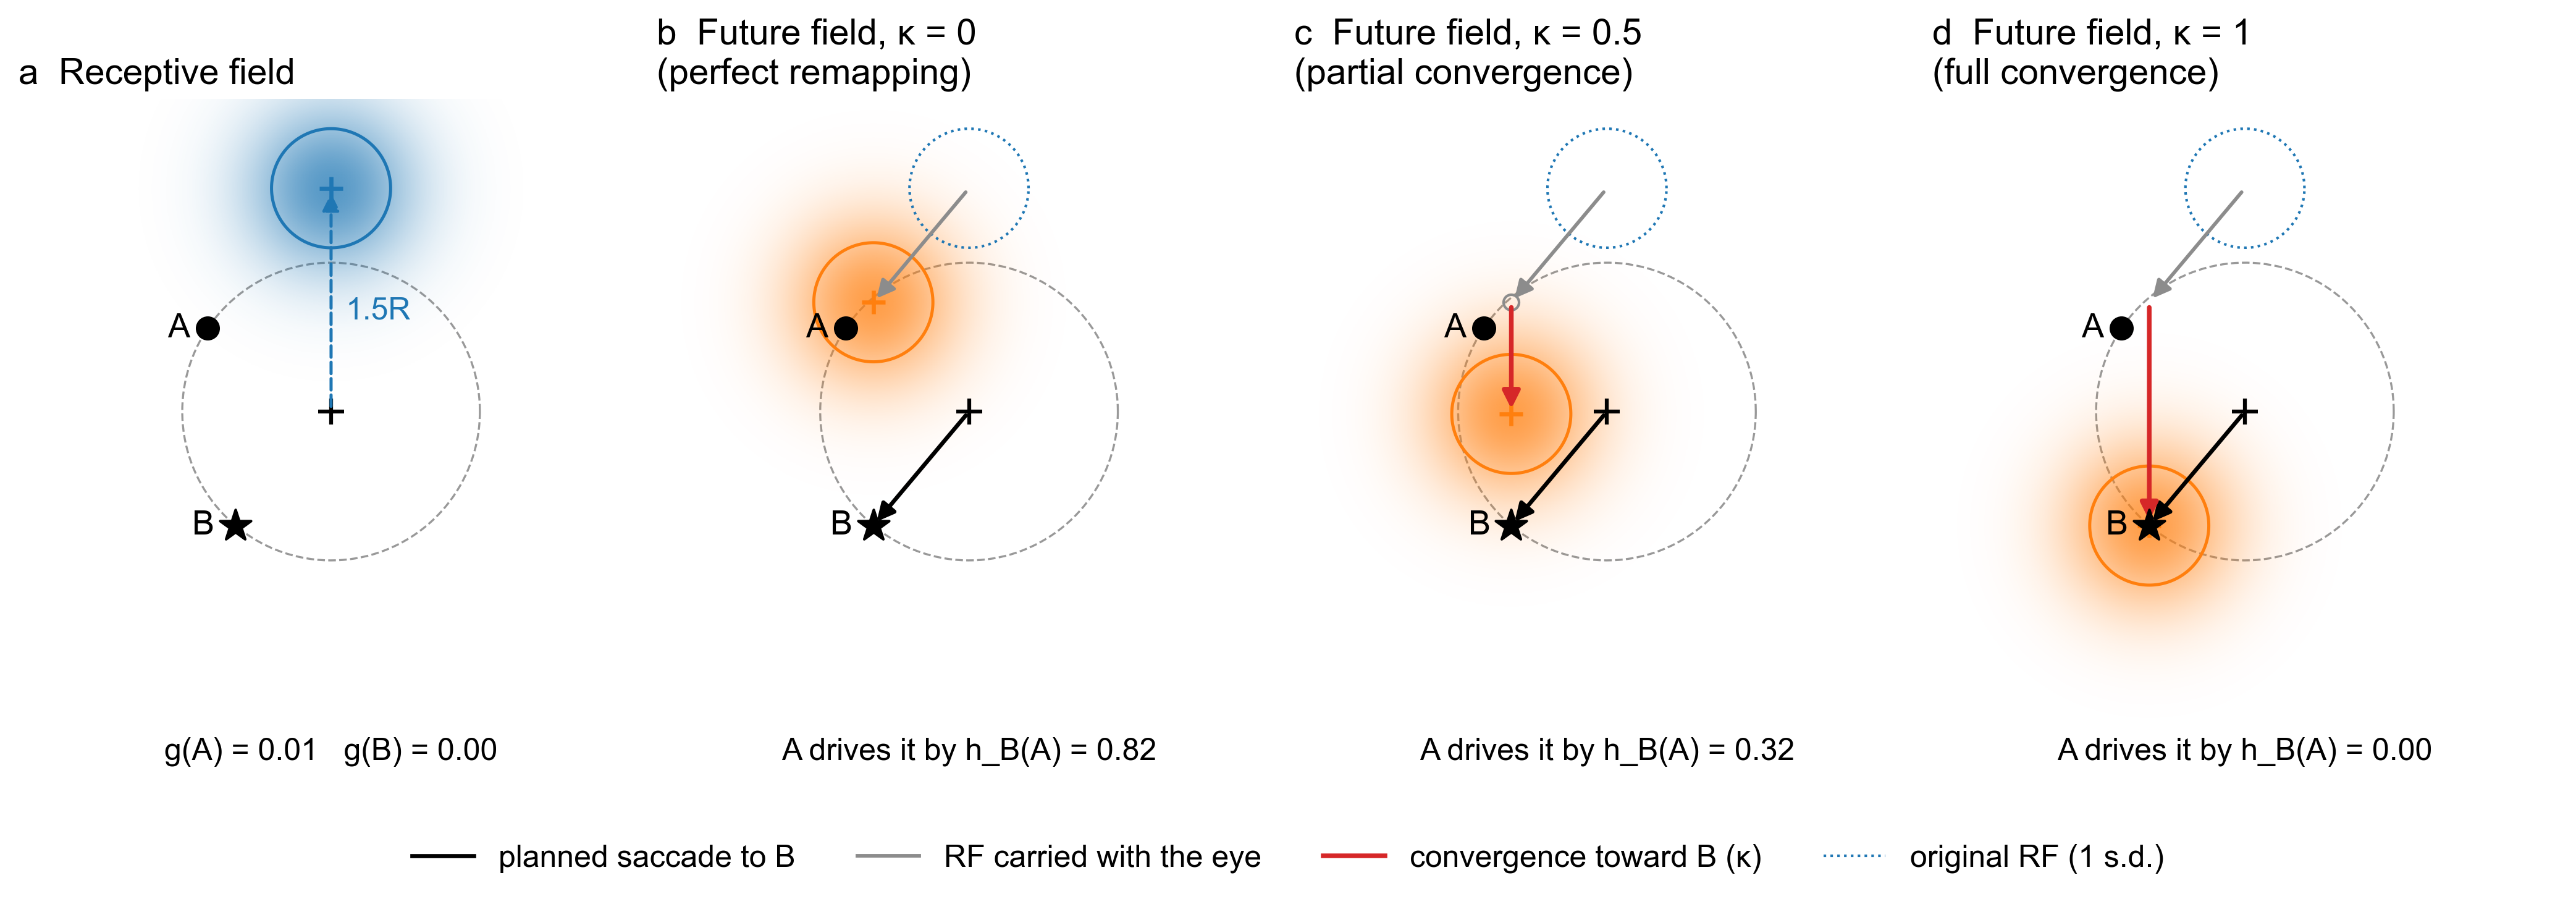

In [4]:
def gauss_image(ax, cx, cy, sigma, color, lim):
    from matplotlib.colors import to_rgb
    xs = np.linspace(-lim, lim, 400)
    X, Y = np.meshgrid(xs, xs)
    Z = fdl.gauss(X, Y, cx, cy, sigma)
    rgba = np.zeros(Z.shape + (4,))
    rgba[..., :3] = to_rgb(color)
    rgba[..., 3] = 0.75 * Z
    ax.imshow(rgba, extent=(-lim, lim, -lim, lim), origin='lower', zorder=1)
    ax.contour(X, Y, Z, levels=[np.exp(-0.5)], colors=[color], linewidths=1.2, zorder=2)
    ax.plot(cx, cy, '+', color=color, ms=9, mew=1.6, zorder=5)


def screen_axes(ax, lim):
    t = np.linspace(0, 2 * np.pi, 300)
    ax.plot(np.cos(t), np.sin(t), 'k--', lw=0.8, alpha=0.4, zorder=1)
    ax.plot(0, 0, '+', color='k', ms=10, mew=1.5, zorder=6)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)


def objects(ax, pa, pb):
    ax.scatter(*pa, s=70, color='k', zorder=7)
    ax.scatter(*pb, s=160, marker='*', color='k', zorder=7)
    ax.text(pa[0] - 0.12, pa[1], 'A', ha='right', va='center', fontsize=13, zorder=8)
    ax.text(pb[0] - 0.14, pb[1], 'B', ha='right', va='center', fontsize=13, zorder=8)


def arrow(ax, p0, p1, color, lw=1.6, style='-|>', ls='-'):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle=style, mutation_scale=14, color=color,
                                 lw=lw, ls=ls, shrinkA=2, shrinkB=2, zorder=6))


th = np.radians(SCHEMATIC_THETA_DEG)
pa = np.array(fdl.ring_xy(np.radians(SCHEMATIC_PHI_A_DEG)))
pb = np.array(fdl.ring_xy(np.radians(SCHEMATIC_PHI_B_DEG)))
c = RF_ECC * np.array([np.cos(th), np.sin(th)])
p = dict(theta=th, width=SCHEMATIC_SIGMA)
LIM = 2.1

fig, axes = plt.subplots(1, 1 + len(SCHEMATIC_KAPPAS), figsize=FIGSIZE_SCHEMATIC)
ax = axes[0]
screen_axes(ax, LIM)
gauss_image(ax, *c, SCHEMATIC_SIGMA, RF_COLOR, LIM)
arrow(ax, (0, 0), c, RF_COLOR, lw=1.2, style='-|>', ls='--')
ax.text(c[0] + 0.1, c[1] * 0.45, f'{RF_ECC:g}R', color=RF_COLOR, fontsize=12, va='center')
objects(ax, pa, pb)
m = fdl.DistanceFutureFieldModel(RF_ECC, 0.0)
ax.set_title('a  Receptive field', loc='left', fontsize=14)
ax.text(0.5, -0.02, f'g(A) = {m.rf(*pa, p):.2f}   g(B) = {m.rf(*pb, p):.2f}',
        transform=ax.transAxes, ha='center', va='top', fontsize=12)

for i, (ax, kappa) in enumerate(zip(axes[1:], SCHEMATIC_KAPPAS)):
    m = fdl.DistanceFutureFieldModel(RF_ECC, kappa)
    screen_axes(ax, LIM)
    perfect = pb + c
    conv = pb + (1 - kappa) * c
    # the receptive field it was remapped from, as a ghost
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(c[0] + SCHEMATIC_SIGMA * np.cos(t), c[1] + SCHEMATIC_SIGMA * np.sin(t), color=RF_COLOR,
            lw=1.0, ls=':', zorder=2)
    gauss_image(ax, *conv, SCHEMATIC_SIGMA, FF_COLOR, LIM)
    arrow(ax, (0, 0), pb, 'k', lw=1.6)                        # the planned saccade
    arrow(ax, c, perfect, '0.55', lw=1.4)                     # carried with the eye
    if kappa > 0:
        arrow(ax, perfect, conv, 'tab:red', lw=1.8)           # convergence toward B
        if kappa < 1:
            ax.plot(*perfect, 'o', mfc='none', mec='0.55', ms=6, zorder=5)
    objects(ax, pa, pb)
    title = {0.0: 'perfect remapping', 1.0: 'full convergence'}.get(kappa, 'partial convergence')
    ax.set_title(f'{"bcd"[i]}  Future field, κ = {kappa:g}\n({title})', loc='left', fontsize=14)
    ax.text(0.5, -0.02, f'A drives it by h_B(A) = {m.future_field(*pa, *pb, p):.2f}',
            transform=ax.transAxes, ha='center', va='top', fontsize=12)

from matplotlib.lines import Line2D
handles = [Line2D([], [], color='k', lw=1.6, label='planned saccade to B'),
           Line2D([], [], color='0.55', lw=1.4, label='RF carried with the eye'),
           Line2D([], [], color='tab:red', lw=1.8, label='convergence toward B (κ)'),
           Line2D([], [], color=RF_COLOR, lw=1.0, ls=':', label='original RF (1 s.d.)')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=12,
           bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(w_pad=0.5)
plt.show()